# Figure 3 Supplement 1: Stopping-model fit quality

Does the fitted stopping model reproduce the data it was fit to? Each subject
is simulated `SIM_REPS` times over their own trials (same block, step
statistics and trial count) from their main fit, and the simulated data are
compared with the real data.

- **Row 1 — RT distributions** per OL block (raw blocks 1–6: low SNR 1–3, high
  SNR 4–6; no-penalty, coin-penalty and step-penalty conditions in order),
  pooled over subjects; the last bin (15+) collects RT ≥ 15.
- **Row 2 — accuracy vs. RT**, same layout (RT bins with ≥ 20 trials). RT = 1
  responses (key pressed on the first frame) are anticipations with a random
  choice in the model.
- **Row 3 — per subject and block**, data vs. model: fraction of responses with
  RT ≤ 2 steps, median RT, accuracy, and fraction of trials in which the pigeon
  hit the screen edge.

**Data:** `get_stopping_model_trials('OL', 1–6)` (the trials the model was fit
to). Fits: `data/processed/stopping_fits_main.pkl`. All subject-blocks are
included, also those whose plateau sits at a fit limit
(`get_plateau_at_limit`): the model still describes their behavior (random
responding, or committing on any movement), so they belong in a test of fit
quality; their count is printed.

**Conventions:** black = data, blue = model. Replaces the old Figure03S01
(congruence by RT; archived in `notebooks/archive/`).

In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label
from pigeon.stopping import get_plateau_at_limit, get_stopping_model_trials, simulate_stopping_data_table

PROCESSED = Path('../data/processed')

In [2]:
SIM_REPS = 5
SIM_SEED = 11
BLOCKS = ['B1', 'B2', 'B3', 'B4', 'B5', 'B6']
BLOCK_TITLES = {'B1': 'Low SNR\nno penalty', 'B2': 'Low SNR\ncoin penalty', 'B3': 'Low SNR\nstep penalty',
                'B4': 'High SNR\nno penalty', 'B5': 'High SNR\ncoin penalty', 'B6': 'High SNR\nstep penalty'}

trials = get_stopping_model_trials('OL', [1, 2, 3, 4, 5, 6])
fits = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits = fits[fits.task == 'OL']
sim = simulate_stopping_data_table(trials, fits, group_col='condition', num_reps=SIM_REPS,
                                   rng=np.random.default_rng(SIM_SEED))
l_limit = get_plateau_at_limit(fits)
print(f'{len(trials):,} real trials, {len(sim):,} simulated; {fits.subject_index.nunique()} subjects, '
      f'{len(fits)} subject-blocks ({int(l_limit.sum())} with the plateau at a fit limit, included)')

OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


38,423 real trials, 192,115 simulated; 60 subjects, 359 subject-blocks (12 with the plateau at a fit limit, included)


In [3]:
MAX_RT = 15
MIN_ACC_TRIALS = 20
rt_ax = np.arange(1, MAX_RT + 1)

def _rt_dist(t):
    return t.RT.clip(upper=MAX_RT).value_counts(normalize=True).reindex(rt_ax, fill_value=0.0)

def _acc_by_rt(t):
    a = t.groupby(t.RT.clip(upper=MAX_RT)).correct.agg(['mean', 'size']).reindex(rt_ax)
    return a['mean'].where(a['size'] >= MIN_ACC_TRIALS * (SIM_REPS if 'rep' in t else 1))

def _subject_stats(t):
    g = t.groupby(['subject_index', 'condition'])
    return pd.DataFrame({'P(RT ≤ 2)': g.RT.apply(lambda r: np.mean(r <= 2)),
                         'Median RT (steps)': g.RT.median(),
                         'Accuracy': g.correct.mean(),
                         'Wall-hit fraction': g.wall_hit.mean()})

stats_real, stats_sim = _subject_stats(trials), _subject_stats(sim)
STAT_NAMES = list(stats_real.columns)
rows = []
for name in STAT_NAMES:
    rho, p = scipy.stats.spearmanr(stats_real[name], stats_sim[name].reindex(stats_real.index))
    rows.append({'statistic': name, 'Spearman rho': rho, 'p': p, 'n subject-blocks': len(stats_real),
                 'median data': stats_real[name].median(), 'median model': stats_sim[name].median()})
display(pd.DataFrame(rows).set_index('statistic').round(3))

# Largest RT-distribution mismatches, for the record.
mis = pd.DataFrame({b: _rt_dist(sim[sim.condition == b]) - _rt_dist(trials[trials.condition == b]) for b in BLOCKS})
print('model − data P(RT), largest absolute differences:')
print(mis.stack().abs().sort_values(ascending=False).head(6).round(3))

,Spearman rho,p,n subject-blocks,median data,median model
statistic,,,,,
P(RT ≤ 2),0.888,0.0,359,0.000,0.008
Median RT (steps),0.984,0.0,359,4.000,4.000
Accuracy,0.934,0.0,359,0.828,0.826
Wall-hit fraction,0.945,0.0,359,0.112,0.107


model − data P(RT), largest absolute differences:
RT    
4   B6    0.062
    B5    0.050
3   B5    0.035
5   B6    0.031
3   B6    0.028
    B1    0.028
dtype: float64


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


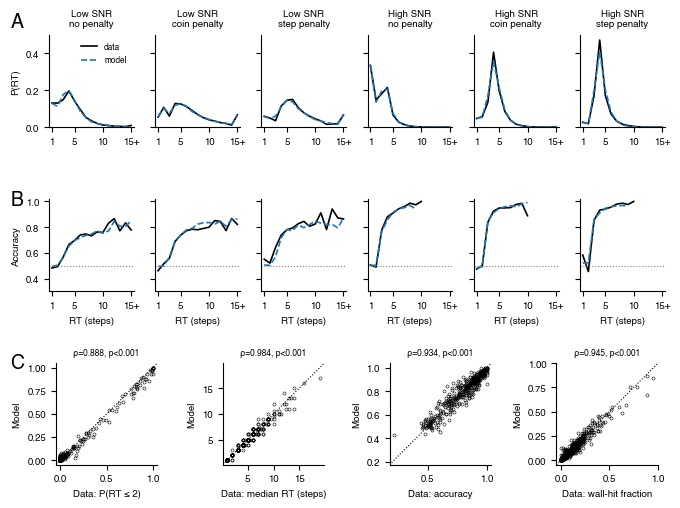

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S01.pdf (+ .png)


In [4]:
CM = 1 / 2.54
FS = 7
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})
MODEL = 'tab:blue'

fig = plt.figure(figsize=(17 * CM, 13 * CM))
outer = gridspec.GridSpec(3, 1, figure=fig, hspace=0.75, height_ratios=[1, 1, 1.1],
                          left=0.07, right=0.99, bottom=0.08, top=0.92)
row1 = gridspec.GridSpecFromSubplotSpec(1, 6, subplot_spec=outer[0], wspace=0.25)
row2 = gridspec.GridSpecFromSubplotSpec(1, 6, subplot_spec=outer[1], wspace=0.25)
row3 = gridspec.GridSpecFromSubplotSpec(1, 4, subplot_spec=outer[2], wspace=0.45)
ax_rt = [fig.add_subplot(row1[i]) for i in range(6)]
ax_acc = [fig.add_subplot(row2[i]) for i in range(6)]
ax_st = [fig.add_subplot(row3[i]) for i in range(4)]

for bi, b in enumerate(BLOCKS):
    r, s = trials[trials.condition == b], sim[sim.condition == b]
    ax = ax_rt[bi]
    ax.plot(rt_ax, _rt_dist(r), 'k-', lw=1.2, label='data')
    ax.plot(rt_ax, _rt_dist(s), '--', color=MODEL, lw=1.2, label='model')
    ax.set_title(BLOCK_TITLES[b])
    ax.set_ylim(0, 0.5)
    ax = ax_acc[bi]
    ax.plot(rt_ax, _acc_by_rt(r), 'k-', lw=1.2)
    ax.plot(rt_ax, _acc_by_rt(s), '--', color=MODEL, lw=1.2)
    ax.axhline(0.5, color='0.5', ls=':', lw=0.8)
    ax.set_ylim(0.3, 1.02)
    ax.set_xlabel('RT (steps)')
    for a in (ax_rt[bi], ax_acc[bi]):
        a.set_xlim(0.5, MAX_RT + 0.5)
        a.set_xticks([1, 5, 10, 15])
        a.set_xticklabels(['1', '5', '10', '15+'])  # last bin: RT >= 15
        if bi > 0:
            a.set_yticklabels([])
ax_rt[0].set_ylabel('P(RT)')
ax_acc[0].set_ylabel('Accuracy')
ax_rt[0].legend(fontsize=6, frameon=False, loc='upper right')

for ax, name in zip(ax_st, STAT_NAMES):
    x, y = stats_real[name], stats_sim[name].reindex(stats_real.index)
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    pad = 0.05 * (hi - lo)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], 'k:', lw=0.8)
    ax.plot(x, y, 'ko', mfc='none', ms=2.2, mew=0.4)
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_aspect('equal')
    ax.set_xlabel(f'Data: {name[0].lower() + name[1:] if not name.startswith("P(") else name}')
    ax.set_ylabel('Model')
    rho, p = scipy.stats.spearmanr(x, y)
    ax.set_title(f'ρ={rho:.3f}, p{"<0.001" if p < 0.001 else f"={p:.3f}"}', fontsize=6)

for ax in ax_rt + ax_acc + ax_st:
    ax.spines[['top', 'right']].set_visible(False)
add_panel_label(ax_rt[0], 'A', dx=-0.45, dy=1.25)
add_panel_label(ax_acc[0], 'B', dx=-0.45, dy=1.1)
add_panel_label(ax_st[0], 'C', dx=-0.45, dy=1.1)

out = FIGURES_DIR / 'Figure03_S01.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Interpretation

(Filled in after review.)